In [1]:
import os
from copy import copy

import numpy as np
import pandas as pd
import umap
import pickle
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib as mpl

import scanpy as sc
import anndata
import scanpy.external as sce

from scarches.models.scpoli import scPoli


/home/xuq44/miniconda3/envs/scarches/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/xuq44/miniconda3/envs/scarches/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/xuq44/miniconda3/envs/scarches/lib/python3.9/site-packages/uma

In [3]:
project_dir = '/home/xuq44/projects/scPDAC'
sc.settings.figdir = f'{project_dir}/figures/'
fig_dir = f'{project_dir}/figures/'

In [4]:
gns = copy(mpl.cm.Blues)
gns.set_under("lightgray")

plate_level_all0 = pd.read_csv(f"{project_dir}/data/db/pdac_color.txt",
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'



In [ ]:

def run_scpoli(adata_all, celltype_key):
    early_stopping_kwargs = {
        "early_stopping_metric": "val_prototype_loss",
        "mode": "min",
        "threshold": 0,
        "patience": 20,
        "reduce_lr": True,
        "lr_patience": 13,
        "lr_factor": 0.1,
    }

    scpoli_model = scPoli(
        adata=adata_all,
        unknown_ct_names=['nan'],
        condition_key='condition',
        cell_type_keys=[celltype_key],
        embedding_dim=3,
        hidden_layer_sizes=[int(np.sqrt(adata_all.shape[0]))]
    )

    scpoli_model.train(
        n_epochs=50,
        pretraining_epochs=40,
        early_stopping_kwargs=early_stopping_kwargs,
        eta=5,
        alpha_epoch_anneal=100
    )
    adata_all.obsm["X_scPoli"] = scpoli_model.get_latent(
        adata_all.X, 
        adata_all.obs["condition"].values,
        mean=True
    )

    sc.pp.neighbors(adata_all, use_rep="X_scPoli")
    # sc.tl.leiden(adata_all, resolution=10.0)
    sc.tl.umap(adata_all)

    return adata_all

def run_harmony(adata):
    sce.pp.harmony_integrate(adata, 'condition')
    sc.pp.neighbors(adata, use_rep='X_pca_harmony', n_pcs=30)
    sc.tl.umap(adata)
    return adata


In [ ]:
adata = sc.read_h5ad(f'{project_dir}/data/Ryo_Organoid/cancer_caf_merged.h5ad')

adata.obs['celltype'] = adata_css.obs['celltype']
adata2 = run_scpoli(adata, 'celltype')

adata2.write_h5ad(f'{project_dir}/data/Ryo_Organoid/cancer_caf_scpoli.h5ad', compression="gzip")


Embedding dictionary:
 	Num conditions: 7
 	Embedding dim: 3
Encoder Architecture:
	Input Layer in, out and cond: 3000 181 3
	Mean/Var Layer in/out: 181 10
Decoder Architecture:
	First Layer in, out and cond:  10 181 3
	Output Layer in/out:  181 3000 

 |--------------------| 2.0%  - val_loss: 1055.8783334585 - val_cvae_loss: 1055.8783334585

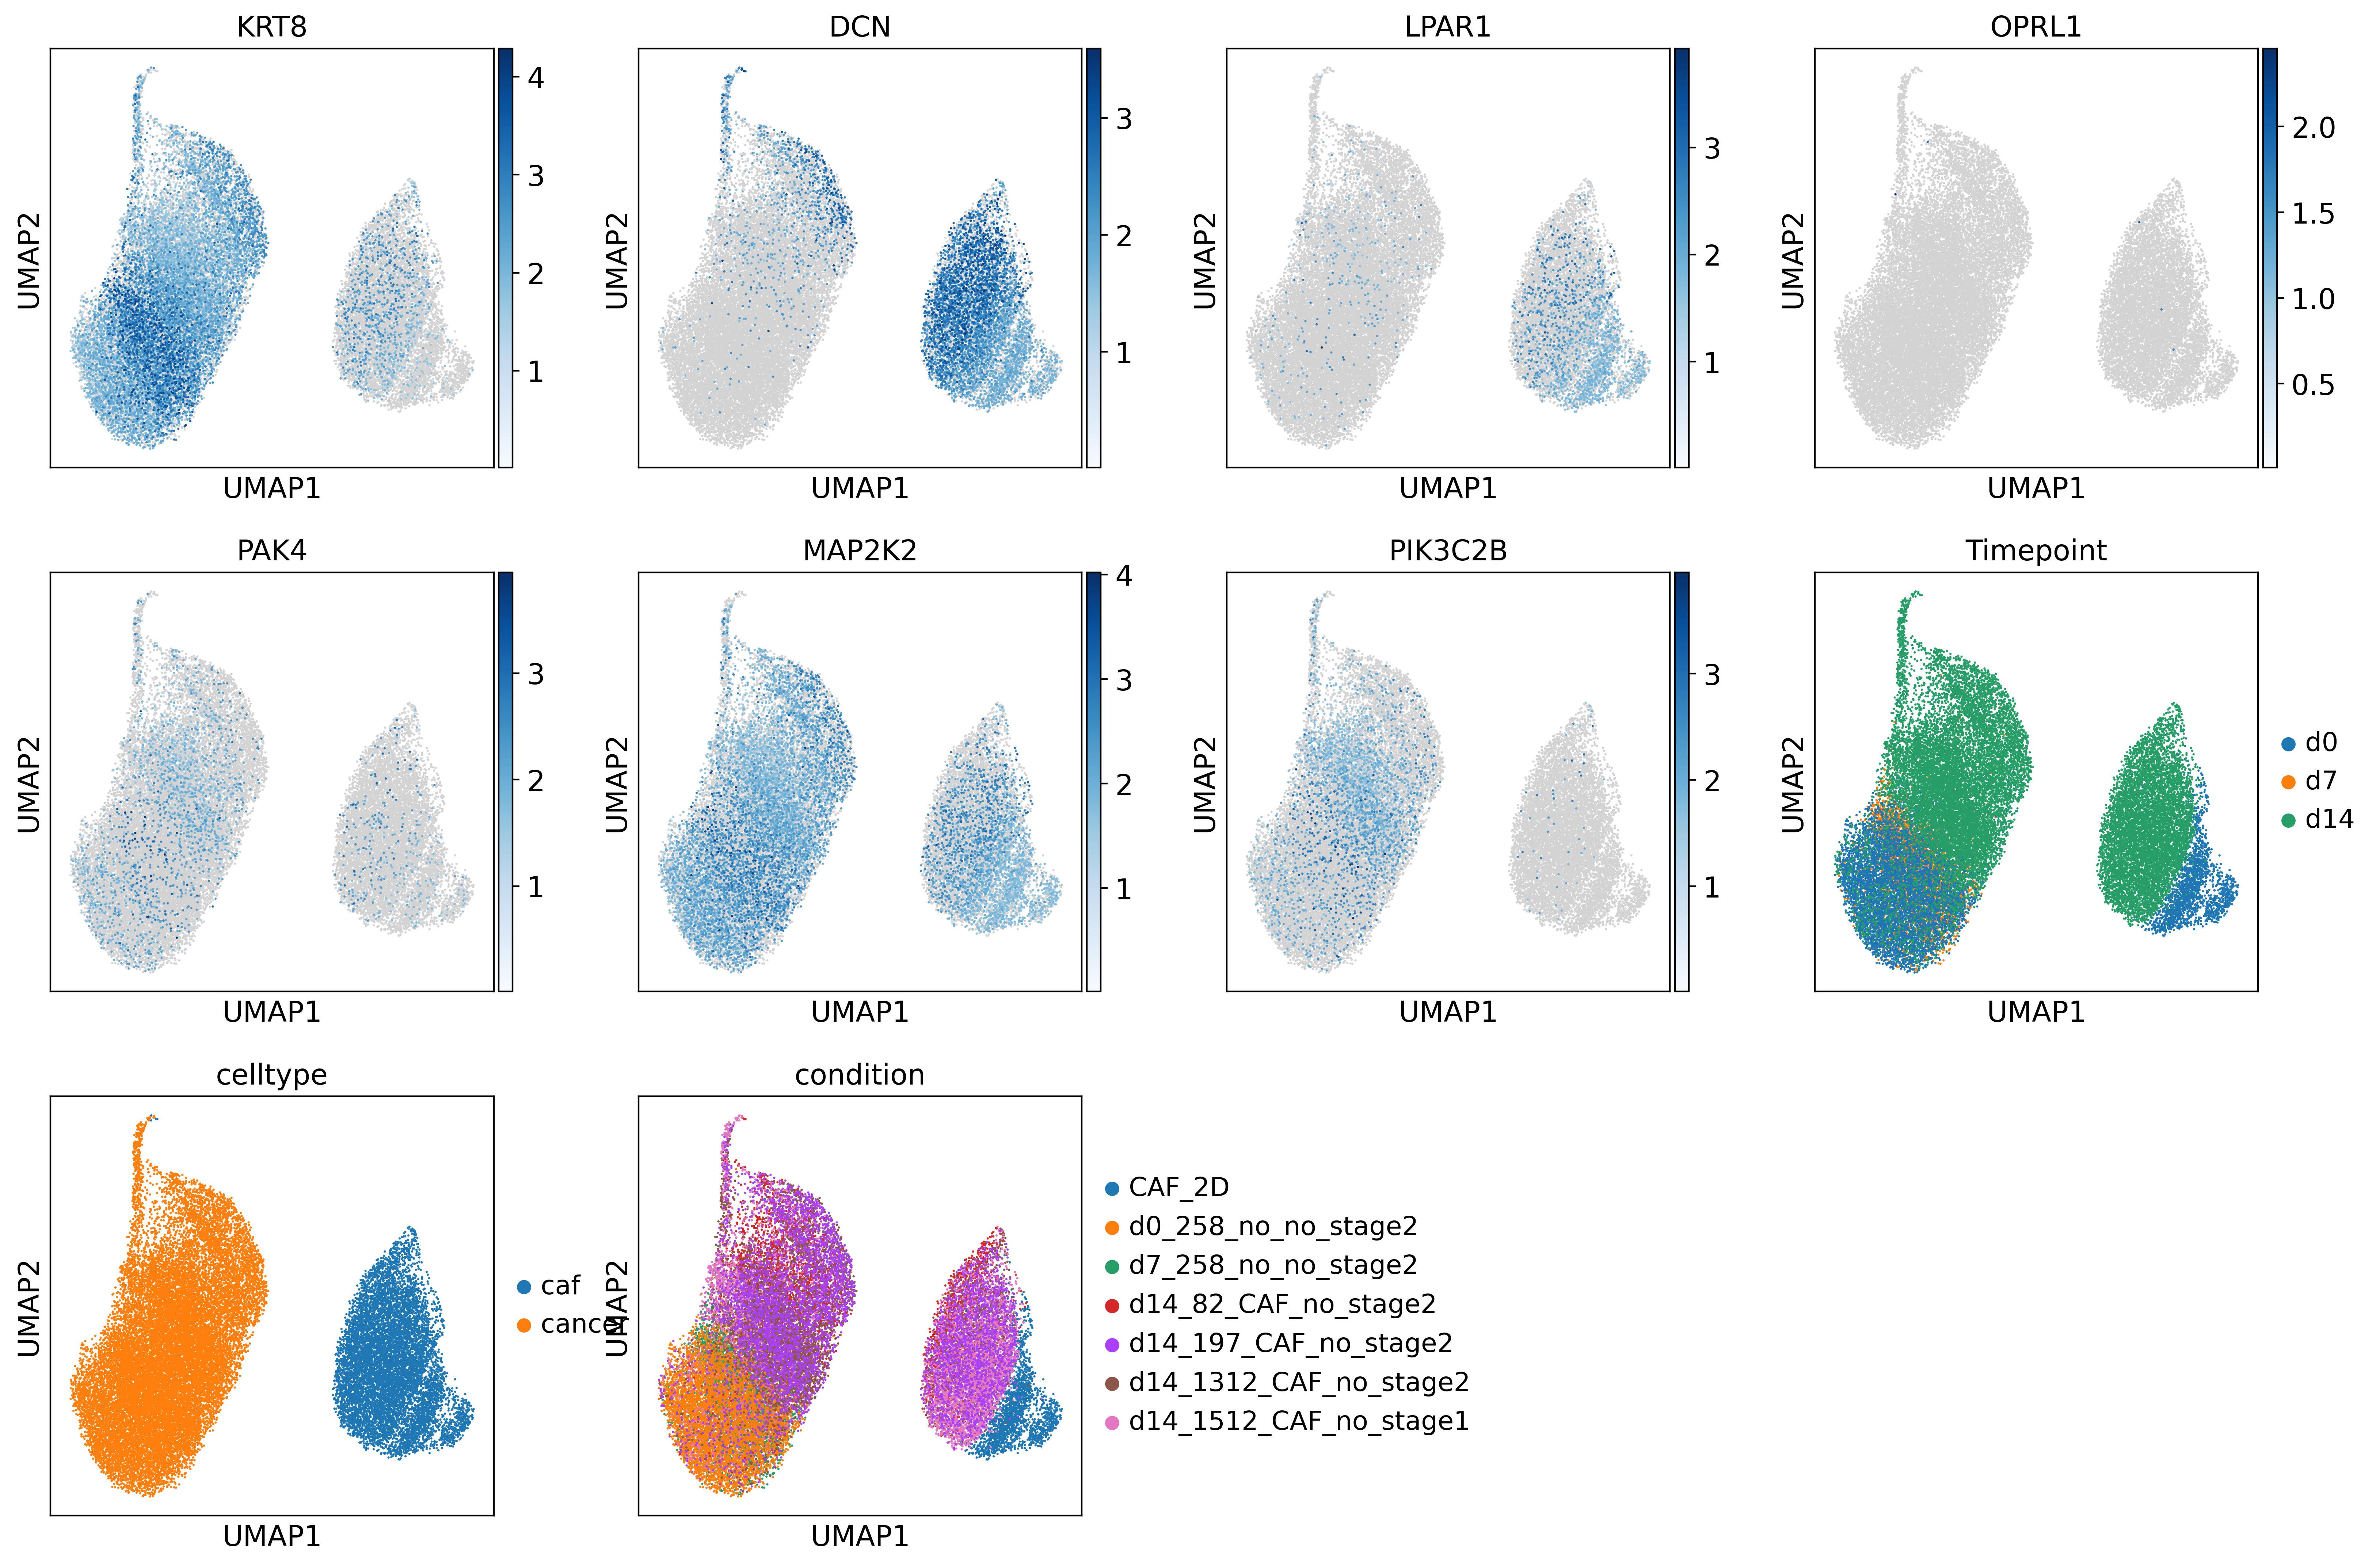

In [67]:
sc.pl.umap(adata2, color=['KRT8','DCN','LPAR1', 'OPRL1', 'PAK4', 'MAP2K2', 
                          'PIK3C2B', 'Timepoint','celltype', 'condition'], 
           color_map=gns, size=5, vmin=0.01)

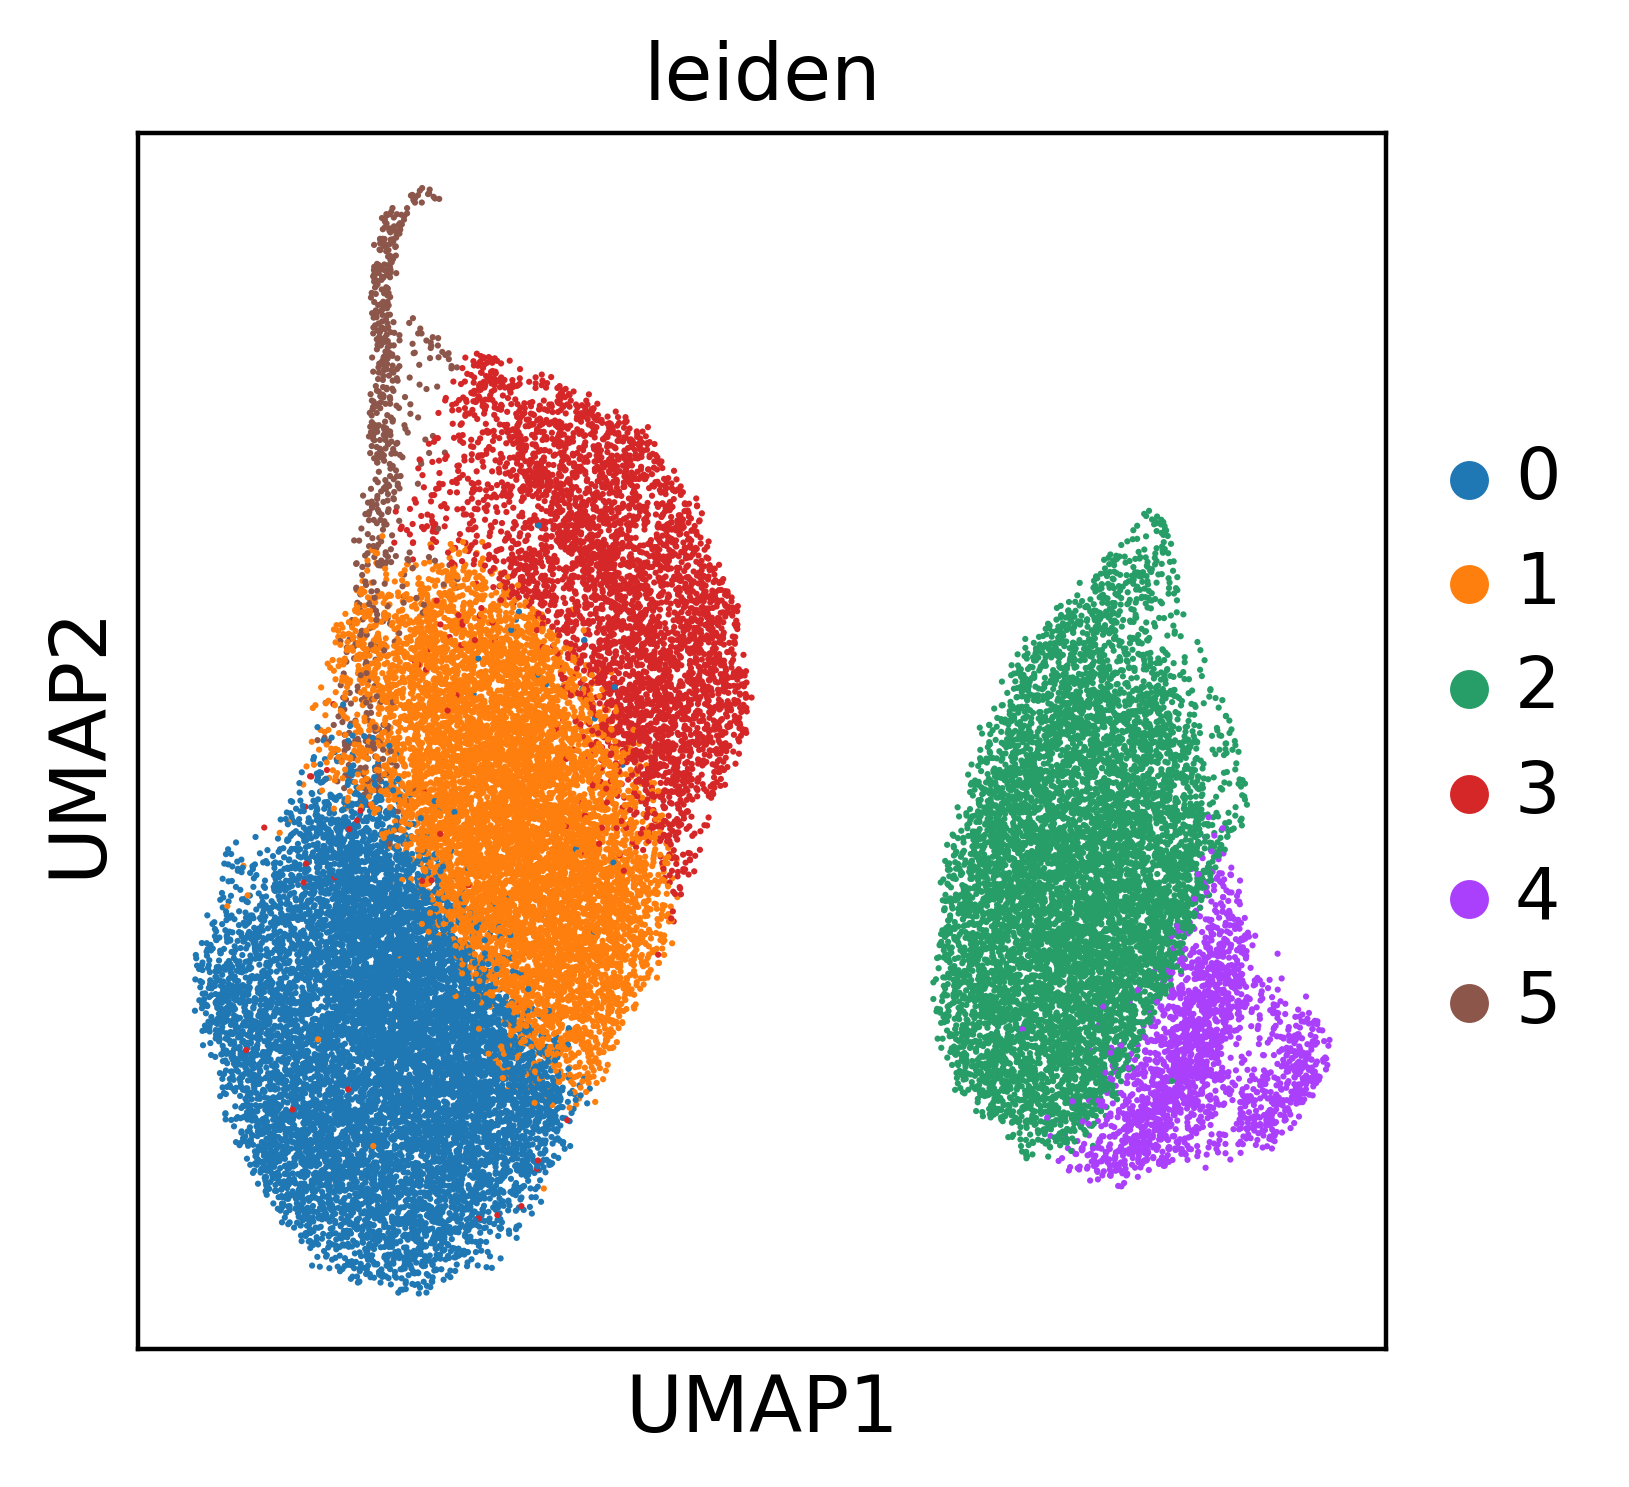

In [ ]:
sc.tl.leiden(adata2, resolution=0.5)
sc.pl.umap(adata2, color=['leiden'], color_map=gns, size=5, vmin=0.01)